# 02 · Exploratory analysis

Descriptive evidence on the three trends at the heart of the paper:

1. **Intangible capital deepening:** how fast has the stock of intellectual property products (IPP) grown in finance compared with other industries?
2. **The labour share:** has the share of value added paid to workers fallen faster in finance?
3. **Productivity and pay:** has real output per worker separated from real pay per worker?

All aggregates are value-added weighted (sum of numerators / sum of denominators), so large industries count more.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "exgap").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from exgap.build_panel import load_panel
from exgap.stats import set_style, savefig, save_table, PALETTE
set_style()
df = load_panel()
df["group"] = np.select([df.finance == 1, df.information == 1], ["Finance & insurance", "Information"], "Other industries")
print(df.shape, df.year.min(), df.year.max())

(1856, 61) 1997 2025


## Table 1. Descriptive statistics

In [3]:
vars_ = {"labor_share": "Labour share", "log_ipp_pw": "log real IPP capital per worker (index)",
         "ipp_intensity": "IPP stock / value added",
         "eq_intensity": "Equipment stock / value added", "ipp_share_of_capital": "IPP share of fixed assets",
         "g_ipp_stock": "IPP stock growth (log)", "productivity": "Real VA per FTE (2017 $)",
         "pay_real": "Real pay per FTE (2017 $)", "prod_pay_gap": "Productivity-pay gap (log pts)"}
vars_ = {k: v for k, v in vars_.items() if k in df}
rows = []
for label, sub in [("All", df), ("Finance", df[df.finance == 1]), ("Non-finance", df[df.finance == 0])]:
    d = sub[list(vars_)].describe().T[["count", "mean", "std", "min", "50%", "max"]]
    d.insert(0, "sample", label)
    rows.append(d.rename(index=vars_))
table1 = pd.concat(rows)
save_table(table1.round(3), "table1_descriptives", caption="Descriptive statistics")
table1.round(3)

,sample,count,mean,std,min,50%,max
Labour share,All,1856.0,0.568,0.199,0.080,0.581,2.171
log real IPP capital per worker (index),All,1792.0,-9.398,1.309,-13.516,-9.311,-5.773
IPP stock / value added,All,1856.0,0.218,0.415,0.000,0.075,3.581
Equipment stock / value added,All,1856.0,0.692,0.813,0.034,0.468,6.903
IPP share of fixed assets,All,1827.0,0.136,0.182,0.000,0.058,0.849
IPP stock growth (log),All,1792.0,0.065,0.084,-0.290,0.057,0.727
Real VA per FTE (2017 $),All,1792.0,196428.898,210373.158,15993.359,134378.597,2361206.897
Real pay per FTE (2017 $),All,1792.0,85126.084,43041.920,23856.938,76949.511,302751.442
Productivity-pay gap (log pts),All,1792.0,0.119,0.396,-0.847,0.036,2.401
Labour share,Finance,87.0,0.624,0.276,0.304,0.506,2.171


## Figure 1. Labour share by industry group (value-added weighted)

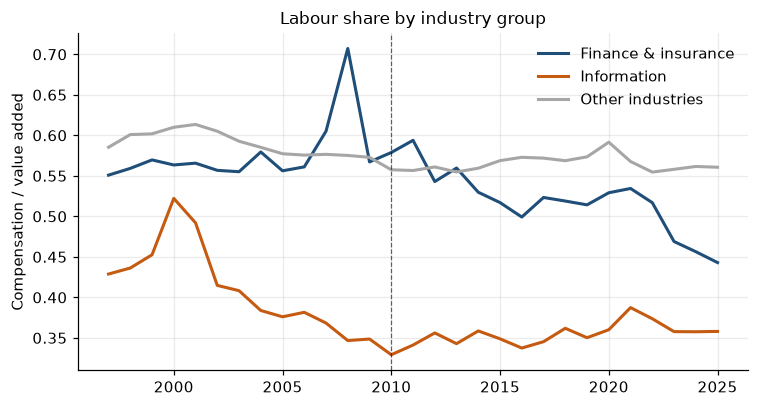

In [4]:
agg = (df.groupby(["year", "group"]).apply(lambda g: pd.Series({
        "labor_share": g["comp"].sum() / g["va_nom"].sum(),
        "ipp_intensity": g["ipp_stock"].sum(min_count=1) / g.loc[g.ipp_stock.notna(), "va_nom"].sum()}))
        .reset_index())
colors = {"Finance & insurance": PALETTE["finance"], "Information": PALETTE["information"], "Other industries": PALETTE["other"]}
fig, ax = plt.subplots(figsize=(7, 3.8))
for gname, g in agg.groupby("group"):
    ax.plot(g.year, g.labor_share, label=gname, color=colors[gname], lw=2)
ax.axvline(2010, ls="--", color="k", lw=0.8, alpha=0.6)
ax.set_ylabel("Compensation / value added"); ax.legend()
ax.set_title("Labour share by industry group")
savefig(fig, "fig1_labor_share_groups"); plt.show()

## Figure 2. Intangible (IPP) capital intensity

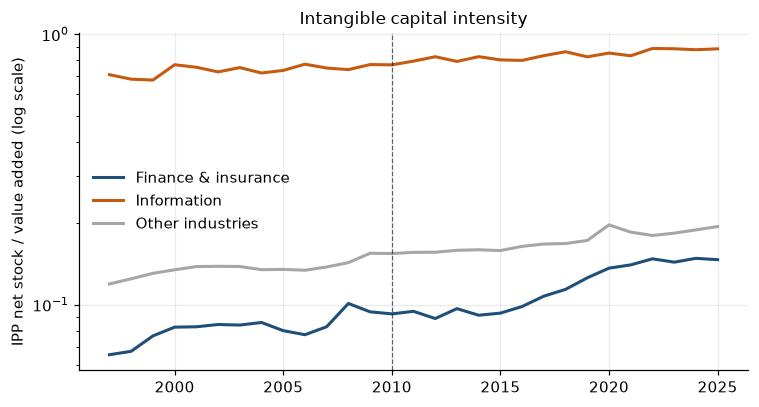

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for gname, g in agg.groupby("group"):
    ax.plot(g.year, g.ipp_intensity, label=gname, color=colors[gname], lw=2)
ax.set_yscale("log"); ax.axvline(2010, ls="--", color="k", lw=0.8, alpha=0.6)
ax.set_ylabel("IPP net stock / value added (log scale)"); ax.legend()
ax.set_title("Intangible capital intensity")
savefig(fig, "fig2_ipp_intensity_groups"); plt.show()

## Figure 3. IPP capital in finance sub-industries (log scale)
A straight line on a log scale is exponential growth; a steeper slope after 2010 would indicate acceleration.

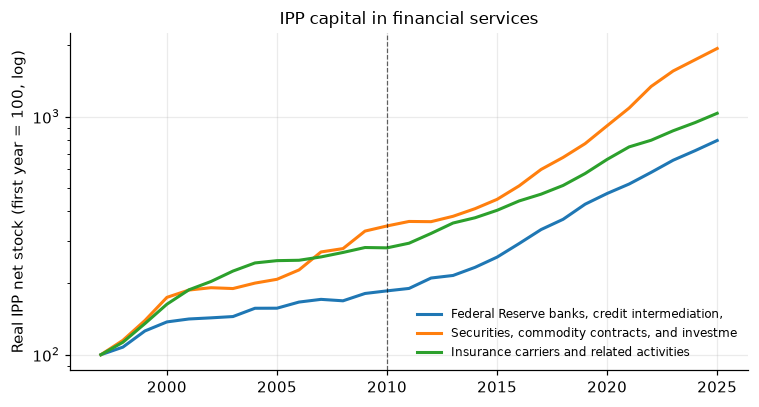

In [6]:
yvar = "ipp_qty" if "ipp_qty" in df and df["ipp_qty"].notna().any() else "ipp_stock"
fin = df[df.finance == 1].dropna(subset=[yvar])
fig, ax = plt.subplots(figsize=(7, 3.8))
for (code, name), g in fin.groupby(["code", "name"]):
    ax.plot(g.year, g[yvar] / g[yvar].iloc[0] * 100, lw=2, label=name[:45])
ax.set_yscale("log"); ax.axvline(2010, ls="--", color="k", lw=0.8, alpha=0.6)
ax.set_ylabel(f"{'Real' if yvar == 'ipp_qty' else 'Nominal'} IPP net stock (first year = 100, log)")
ax.legend(fontsize=8); ax.set_title("IPP capital in financial services")
savefig(fig, "fig3_ipp_finance_subindustries"); plt.show()

## Figure 4. Productivity–pay gap in finance

`prod_pay_gap` = cumulative log growth of real value added per FTE minus cumulative log growth of real pay per FTE (deflated by consumer prices).
It can be decomposed exactly into (i) the fall in the labour share and (ii) the gap between consumer prices and the industry's output prices (Stansbury & Summers, 2018); notebook 03 reports this decomposition.

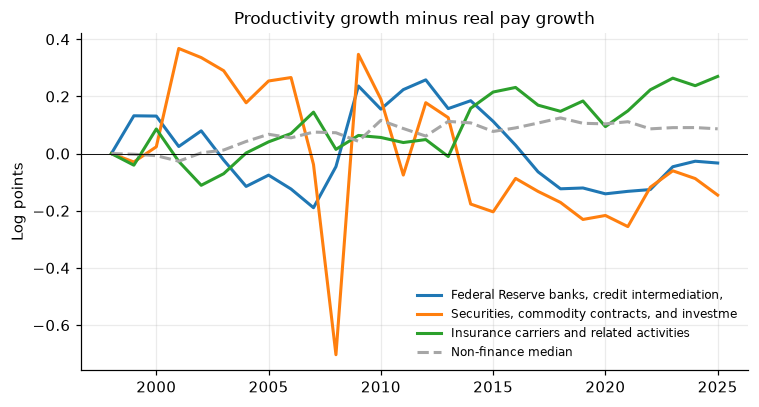

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (code, name), g in df[df.finance == 1].dropna(subset=["prod_pay_gap"]).groupby(["code", "name"]):
    ax.plot(g.year, g.prod_pay_gap, lw=2, label=name[:45])
med = df[df.finance == 0].groupby("year")["prod_pay_gap"].median()
ax.plot(med.index, med.values, color=PALETTE["other"], lw=2, ls="--", label="Non-finance median")
ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("Log points"); ax.legend(fontsize=8)
ax.set_title("Productivity growth minus real pay growth")
savefig(fig, "fig4_prod_pay_gap_finance"); plt.show()

## Figure 5. Long differences: change in IPP intensity vs change in labour share

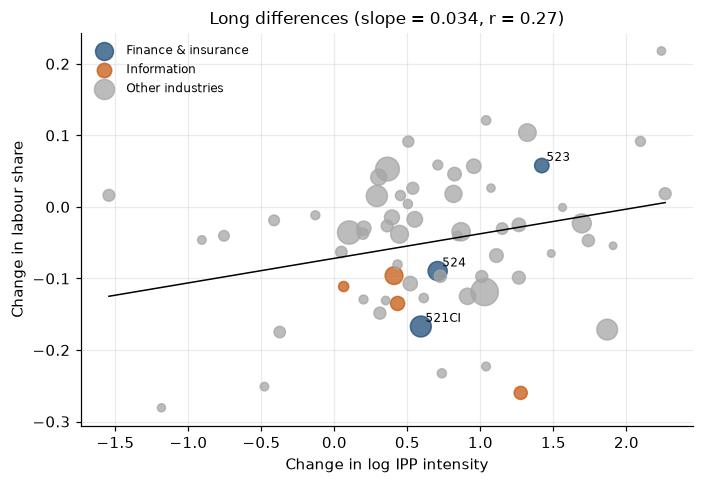

In [8]:
ld = (df.dropna(subset=["log_ipp_intensity", "labor_share"]).sort_values("year").groupby(["code", "name", "group"])
        .agg(y0=("year", "first"), y1=("year", "last"), d_ipp=("log_ipp_intensity", lambda s: s.iloc[-1] - s.iloc[0]),
             d_ls=("labor_share", lambda s: s.iloc[-1] - s.iloc[0]), w=("va_nom", "mean")).reset_index())
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for gname, g in ld.groupby("group"):
    ax.scatter(g.d_ipp, g.d_ls, s=20 + 300 * g.w / ld.w.max(), alpha=0.75, color=colors[gname], label=gname)
b = np.polyfit(ld.d_ipp, ld.d_ls, 1); xs = np.linspace(ld.d_ipp.min(), ld.d_ipp.max(), 50)
ax.plot(xs, np.polyval(b, xs), color="k", lw=1)
for _, r in ld[ld.group == "Finance & insurance"].iterrows():
    ax.annotate(r["code"], (r.d_ipp, r.d_ls), fontsize=8, xytext=(3, 3), textcoords="offset points")
r = np.corrcoef(ld.d_ipp, ld.d_ls)[0, 1]
ax.set_xlabel("Change in log IPP intensity"); ax.set_ylabel("Change in labour share")
ax.set_title(f"Long differences (slope = {b[0]:.3f}, r = {r:.2f})"); ax.legend(fontsize=8)
savefig(fig, "fig5_long_differences"); plt.show()
save_table(ld.round(4), "long_differences", index=False)

## Figure 6. Correlations among the main variables

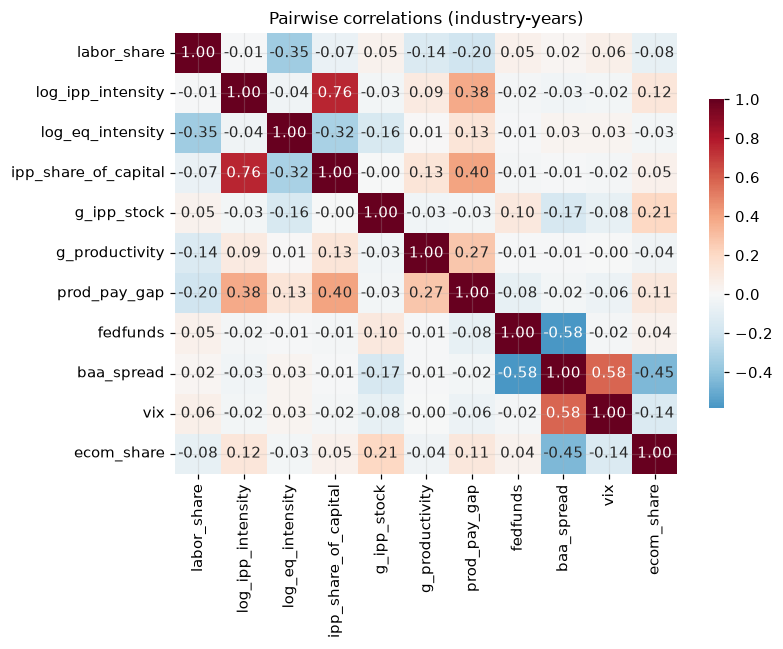

In [9]:
cvars = [v for v in ["labor_share", "log_ipp_intensity", "log_eq_intensity", "ipp_share_of_capital", "g_ipp_stock",
                    "g_productivity", "prod_pay_gap", "fedfunds", "baa_spread", "vix", "ecom_share"] if v in df]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(df[cvars].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Pairwise correlations (industry-years)")
savefig(fig, "fig6_correlations"); plt.show()

## Figure 7. Macro-financial backdrop

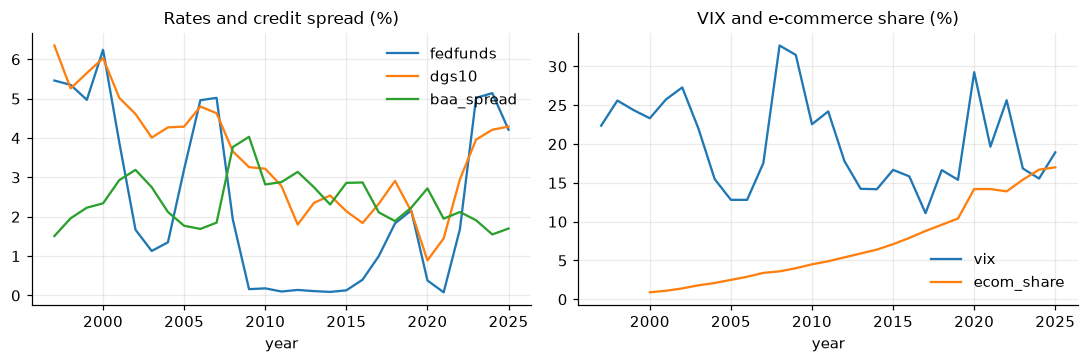

In [10]:
macro = df.groupby("year")[[c for c in ["fedfunds", "dgs10", "baa_spread", "vix", "ecom_share"] if c in df]].first()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
macro[[c for c in ["fedfunds", "dgs10", "baa_spread"] if c in macro]].plot(ax=axes[0]); axes[0].set_title("Rates and credit spread (%)")
macro[[c for c in ["vix", "ecom_share"] if c in macro]].plot(ax=axes[1]); axes[1].set_title("VIX and e-commerce share (%)")
savefig(fig, "fig7_macro_backdrop"); plt.show()